### Import Libraries : Exhaustive list, not all being used

In [1]:
from PIL import Image

import os
dir_path = r"C:\Admin\C Drive\Desktop\CQF Course\Python Labs"

In [2]:
# data manipuation
import pandas as pd
import numpy as np

# panda technical analysis 
import pandas_ta as ta

# data visualization
import matplotlib as mpl

import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = (10,6)
plt.style.use ='seaborn'
plt.rcParams['font.size'] = 8

#-------------------------------------------------------------------------------------------------------------
# statistical visual representation
import seaborn as sns

import cufflinks as cf                                                        # new package - cufflinks
cf.set_config_file(offline=True, theme='pearl',dimensions=((1000,600)))       # cf.set_config() -- (w,h)

import plotly.express as px
px.defaults.width, px.defaults.height = 1000,600

#-------------------------------------------------------------------------------------------------------------
# Self organizing maps(SOM)
from minisom import MiniSom

#-------------------------------------------------------------------------------------------------------------
# K-means clustering(KMC)
from sklearn.cluster import KMeans

# scikit learn(sklearn) package is used primarily for machine learning
# always remember to perform pre-processing and model selcetion before using model implementation
import sklearn
from sklearn.preprocessing import MinMaxScaler,StandardScaler
from sklearn.model_selection import train_test_split,TimeSeriesSplit,cross_val_score,GridSearchCV,RandomizedSearchCV

from sklearn.pipeline import Pipeline

# sklearn evaluation metrics
from sklearn.metrics import precision_recall_curve, roc_curve,RocCurveDisplay,ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, f1_score, recall_score,precision_score,roc_auc_score,auc
from sklearn.metrics import classification_report, confusion_matrix

# Regression
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet

# K-means clustering(KMC)
from sklearn.cluster import KMeans

# Support Vector Machine(SVM)
from sklearn.svm import SVC

# DTEM(Decision Trees and Ensemble Models) - Bagging - Random Forest
from sklearn.ensemble import RandomForestClassifier

# K nearest neighbours(KNN)
from sklearn.neighbors import KNeighborsClassifier

# Principal Component Analysis(PCA)
from sklearn.decomposition import PCA

#-------------------------------------------------------------------------------------------------------------
# DTEM(Decision Trees and Ensemble Models) - Boosting - Gradient Boosting(Extreme Gradient Boosting)
from xgboost import XGBClassifier,plot_importance,to_graphviz

#-------------------------------------------------------------------------------------------------------------
# statistical analysis & optimization
import scipy.stats as scs
import scipy.optimize as sco
from scipy.interpolate import interp1d
from scipy.integrate import simpson
from scipy.interpolate import CubicSpline

# statsmodels is a Python package that provides a complement to scipy for statistical computations
import statsmodels.api as sm
from statsmodels.tsa.api import VAR
from statsmodels.tsa.statespace.varmax import VARMAX
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller, coint, grangercausalitytests
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

#-------------------------------------------------------------------------------------------------------------
# Nelson Siegel Svensson Model
from nelson_siegel_svensson import NelsonSiegelCurve, NelsonSiegelSvenssonCurve
from nelson_siegel_svensson.calibrate import calibrate_ns_ols, calibrate_nss_ols

#-------------------------------------------------------------------------------------------------------------
# SABR(Stochastic Alpha, Beta, Rho)
from pysabr import Hagan2002LognormalSABR
from pysabr import Hagan2002NormalSABR
from pysabr.helpers import year_frac_from_maturity_label

#-------------------------------------------------------------------------------------------------------------
# Shapley values, used in DTEM
import shap

#-------------------------------------------------------------------------------------------------------------
# Quantlib package
from QuantLib import *

#-------------------------------------------------------------------------------------------------------------
# Pyfolio package used for strategy backtesting
import pyfolio as pf

# to reload another python script 
from importlib import reload

# Ignore warnings - optional
import warnings
warnings.filterwarnings('ignore')

# data retrival
import yfinance as yf
 
# float display
pd.options.display.float_format = '{:0.4f}'.format

# operating system
import os

# Image package
from PIL import Image

# table formation
from tabulate import tabulate

# datetime handling
from datetime import datetime

import itertools

Module "zipline.assets" not found; mutltipliers will not be applied to position notionals.


## Credit Default Swap

Credit Default Swap (CDS) is a derivative of a bond or a securitized instruments that involves transfer of a credit risk between two parties. CDS = Credit + Default + Swap, where the 'credit' is linked to bond or loan, 'default' is linked to sensitivity of default event or bankruptcy and 'swap' involves exchange of cashflows. Here, the seller takes the credit risk that the buyer does not wish to shoulder in exchange for a premium over a certain period. The buyer of a CDS contract is seeking insurance against a default of an underlying bond, while the seller is offering a guarantee that the bond will be repaid. The spread of a CDS is the annual amount of the protection buyer must pay the protection seller over the length of the contract, expressed as a percentage of the notional amount.

For example, consider a CDS contract be between two parties say party A and party B. Let Party A be the protection buyer and Party B be the protection seller. The following is the cash flow payment patterns for the above example CDS trade:

**Party A**

No Credit Event: Party A will continue to make premium payment at pre-defined points of time until contract maturity.
Credit Event Occurs: Party A will not pay premium payments due in the future anymore.

**Party B**

No Credit Event: Party B will continue to receive premium payment at pre-defined points of time until contract maturity.
Credit Event Occurs: Party B will have to make good the loss to Party A owing to the credit event occurring.

Generally, the credit event could be any of the four occurances:

- Complete default on payments
- Partial default on payments
- Credit rating downgrade
- Widening credit spreads

However, as these trades are executed on Over the Counter (OTC), both parties can define credit events as per their requirements in the contract at the time of entering into the trade. CDS are generally quoated as spreads. All thing being equal, at any given time, if the maturity of two CDS is the same, then the CDS with a company with a higher (CDS) spread is considered more likely to default by the market.

Application of CDS includes Hedging, Speculation and Capital Structure Arbitrage (CSA).

### Default Modeling

To model the arrival of a credit event, we need to model an unknow random point in time $\tau \in \mathbb{R_+}$

For default risk modeling, we use the default indicator function and survival indicator function which is one minus the default indicator function. The survival indicator function is thus represented as,

$$\begin{equation}
I(t) = 1_{\tau > T}
    \begin{cases}
     1 & \text{if} \ \tau > T\\
     0 & \text{if} \ \tau \leqslant T\\
    \end{cases} 
\end{equation}$$

where τ is the time of default.

### Poisson Processes

For analysis of credit events we use Poisson processes. Poisson processes are usually used to model rare events and discretely countable events such as defaults. It is a discrete time process which gives the probability of default between two time intervals conditional on surviving uptil the initial time point and these inter-arrival times of Poisson process are exponentionally distributed.

We can model the arrival of default as the first jump of a Poisson process with intensity 
$\lambda$ and its associated survival probability 
S(t,T) can be obtained as,
$$S(t,T) = e^{-\lambda (T-t)}  $$

where, λ (also known as) the hazard rate is constant and does not depend on time. Thus, the risk of default is modeled using the survival probability.

In [3]:
# specify lambda
lambda_ = 0.05

# specify tenors
tenors = np.arange(15)

# calculate survival probability
data = pd.DataFrame({'Survival' : np.exp(-lambda_*tenors)})
data['Default'] = 1 - data['Survival']

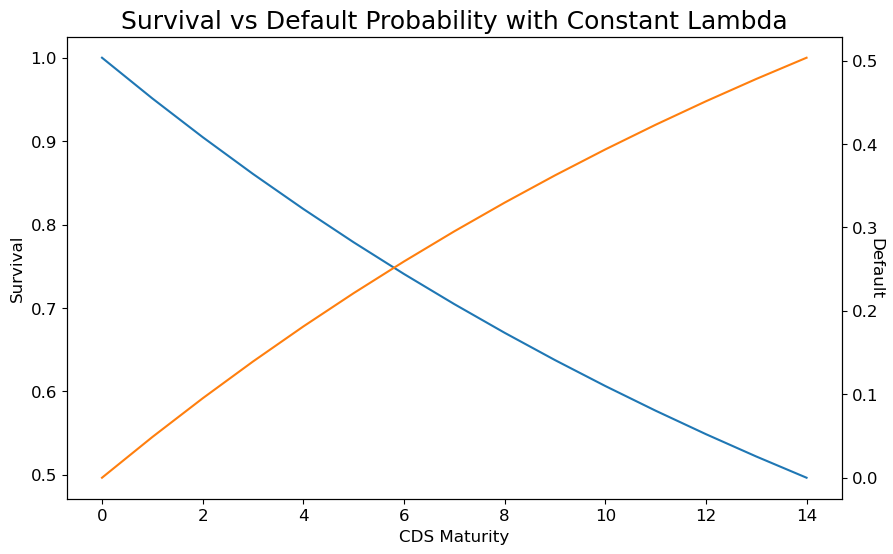

In [4]:
ax = data['Survival'].plot()
ax.set_ylabel('Survival', fontsize = 12)
ax.set_xlabel('CDS Maturity', fontsize = 12)
data['Default'].plot(ax=ax, secondary_y=True,fontsize=12)
plt.ylabel('Default', fontsize=12, rotation=-90)
plt.xlabel('CDS Maturity', fontsize = 12)
plt.title('Survival vs Default Probability with Constant Lambda', fontsize = 18)
plt.show()

If the hazard rate λ is known, we can have the entire term structure of probabilities and use these to estimate the likelihood of the various cashflows in the CDS. Premium payments are estimated using survival probability and default payments using probability of default.

### Inhomogeneous Poisson Processes

For a inhomogeneous Poisson processes, if the intensity $\lambda(t) $ is a non-negative function of time, we can derive the survival probability as

$$S(t) = e^{-\int_{0}^{t}\lambda(s)ds}  $$

Here, the hazard rate is non constant and depends on the time horizon T and the term structure of hazard rates is not flat, but given by λ(T), so we can reach every term structure we desire so as to match the market exactly.

### Survival Probability

The survival probability is a key component in calculation of cash flows and therefore the valuation of a CDS contract. As we know, the occurrence of a credit event is related to the concept of probability of default, which in itself is complement of probability of survial.

Thus, the **Probability of Survival + Probability of default = 1**

The survival probability is not directly observable in the market and has to be implied from traded credit spreads in the market. We then use the CDS spreads and run a bootstrapping algorithm to calculate the survival probability. These survival probabilities are then used to price the CDS contracts.

## CDS Pricing: Basic Model

In CDS pricing, we bootstrap the hazard rates given the premium leg, default leg and the fair spread. The simplified pricing model for CDS is called as the 'Standard Model' or popular known as the 'JP Morgan Approach'

### Mathematical Setup

Discretize the maturity into number of $\Delta t$ so that the corresponding end of period maturities are then expressed as
$$ t_n = n\Delta t$$
The objective is to calculate the cashflow associated with CDS interms of payment that will be made at these time points.


Discount factors are written as functions of forward rates **rn**
$$ D(0,t_n) = e^{-\sum \limits_{k=1}^{n} r_k \Delta t} $$
 
Probability of survival given discretized time and (piecewise constant) hazard rates will then be represented as
$$ S(t_n) = e^{-\sum \limits_{k=1}^{n} \lambda_k \Delta t} $$

Assuming that at time zero, the obligor is solvent, we have 
**$S(t_0)=S(0)=1$**

Premium legs are calculated by multiplying with the corresponding discount factors and probability of survival at each payment dates (time points).

$$ PL_N = S_N \sum \limits_{n=1}^{N} D(0,T_n) S(t_n) (\Delta t_n)$$

where, $\Delta t_n$ is the year fraction corresponding to $t_{n−1}$ −$t_n$ and $S(t_n)$ is the survival probability up to time $t_n$. This accounts for the expected present value of payments made from the buyer A to the seller B.

Default legs are conditional on occurrence of the default event. The exepcted present value of this payment depends on the recovery rate R in the event of default. The loss payment on default is then equal to (1−R) for every $1 of notional principal. Thus, the expected present value of loss payments is given as

$$ DL_N = (1-R) \sum \limits_{n=1}^{N} D(0,t_n) (S(t_{n-1}) - S(t_n)) $$

The probability is given by the probability of surviving until period n−1 and then defaulting in periond.

The fair quots of the spread $S_N$ is such that the expected present value of the payments made by buyer and seller are equal, i.e. $PL_N=DL_N$

Thus, we obtain

$$ S_N = \frac{(1-R) \sum \limits_{n=1}^{N} D(0,t_n) (S(t_{n-1}) - S(t_n))}{\sum \limits_{n=1}^{N} D(0,t_n) S(t_n) (\Delta t_n)} $$

where, $S(t_{n−1})− S(t_n)$ is the marginal probability of survival.

### CDS Boostrapping

We assume that we have a CDS market spreads for increasing maturities $S1,S2,...,S_N$ we can then determine their associated survival probabilities $S(t_1),S(t_2),...,S(t_N)$

First Step (N=1),
$$ S(t_1) = \frac{L}{L+\Delta t_1S_1}$$

where, L=1−R

Second Step (N=2),

$$ S(t_2) = \frac{D(0,t_1) [L - (L + \Delta t_1 S_2)S(t_1)]}{D(0,t_2) (L + \Delta t_2 S_2)} +
\frac{S(T_{1})L}{L+\Delta t_2 S_2}$$

In general, we can write down the expression for $S(t_N)$ as

$$ S(t_N) = \frac{\sum \limits_{n=1}^{N-1} D(0,t_n) [LS(t_{n-1}) - (L + \Delta t_n S_N)S(t_n)]}{D(0,t_N) (L + \Delta t_N S_N)} +\frac{S(t_{N-1})L}{L+\Delta t_N S_N}$$


Thus, we begin with P(T1) and through a process of bootstrapping, we arrive at all 
$P(T_n)$ where, n=1,2,...,N.

### hazard Rate Approximation

Assume today t = 0 and P(t) is survival probability

$S(t_2) = e^{-\lambda t_2}  , S(t_1) = e^{-\lambda t_1} $

so for period T1 to T2
$$\lambda = -\frac{1}{\Delta t}ln\left[\frac{S(t_2)}{S(t_1)}\right] $$

$$pdt \approx \lambda dt$$

**So we can say that probability of default is approximatlly equals hazard rate.**

### Implementation

In [5]:
# subsume list of inputs into a dataframe
df = pd.DataFrame({'Maturity' :[0,1,2,3,4,5],
                   'Df':[1,0.97,0.94,0.92,0.89,0.86],
                   'Spread' :[0,50,77,94,109.5,125]})

# convert bps to decimal
df['Spread'] = df['Spread']/10000

# specify delta_t
df['dt'] = df['Maturity'].diff(periods = 1).fillna(0)

# specify recovery rate, Loss given default
RR = 0.4
L = 1-RR

In [6]:
# initialize the variables
term = term1 = term2 = divider = 0

for i in range(len(df.index)):
    if i == 0:
        df.loc[i,'Survival'] = 1
    elif i == 1:
        df.loc[i, 'Survival'] = L/(L + df.loc[i,'dt']*df.loc[i,'Spread'])
        
    if i > 1:
        terms = 0
        for j in range(1,i):
            term = df.loc[j,'Df']*(L*df.loc[j-1,'Survival'] -(L + df.loc[j,'dt']*df.loc[i,'Spread'])*df.loc[j,'Survival'])
            
            terms = terms + term
        
        divider = df.loc[i,'Df']*(L + df.loc[i,'dt']*df.loc[i,'Spread'])
        term_1 = terms /divider
        
        term_2 = (L*df.loc[i-1,'Survival']) / (L + (df.loc[i,'dt'] * df.loc[i,'Spread']))
        
        df.loc[i,'Survival'] = term_1 + term_2


In [7]:
df['Default'] = 1 - df['Survival']
df

,Maturity,Df,Spread,dt,Survival,Default
0,0,1.0000,0.0000,0.0000,1.0000,0.0000
1,1,0.9700,0.0050,1.0000,0.9917,0.0083
2,2,0.9400,0.0077,1.0000,0.9746,0.0254
3,3,0.9200,0.0094,1.0000,0.9539,0.0461
4,4,0.8900,0.0109,1.0000,0.9289,0.0711
5,5,0.8600,0.0125,1.0000,0.8994,0.1006


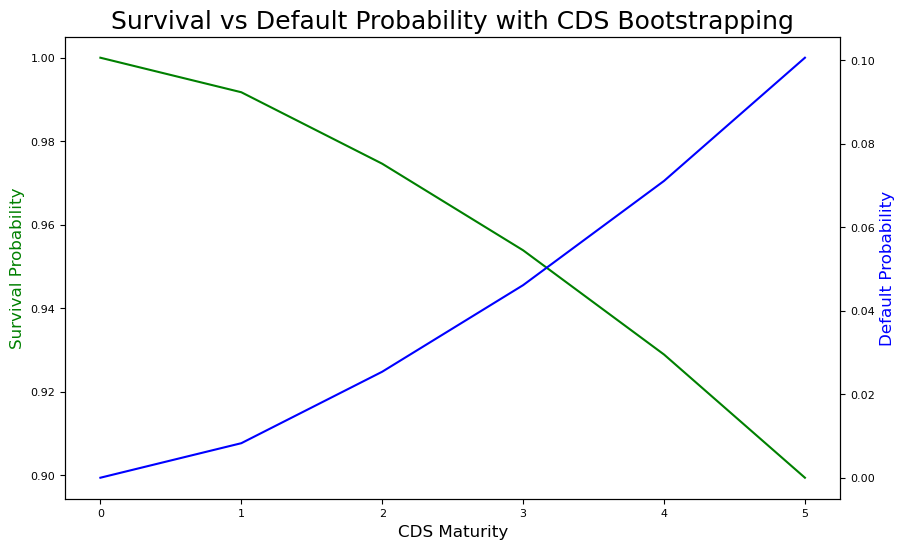

In [8]:
fig, ax1 = plt.subplots()

ax2 = ax1.twinx()
ax1.plot(df.index, df['Survival'], 'g-', label = 'Survival')
ax2.plot(df.index, df['Default'], 'b-', label = 'Default')
ax1.set_xlabel('CDS Maturity', fontsize = 12)
ax1.set_ylabel('Survival Probability', color='g',fontsize = 12)
ax2.set_ylabel('Default Probability', color='b',fontsize = 12)
plt.title('Survival vs Default Probability with CDS Bootstrapping', fontsize = 18)
plt.show()

### User Defined Function

In [9]:
def survival_probability(maturity, discount_factor, spread, recovery, is_plot= False):
    
    # subsume list of inputs into a dataframe
    df = pd.DataFrame({'Maturity' :maturity,
                       'Df':discount_factor,
                       'Spread' :spread})

    # convert bps to decimal
    df['Spread'] = df['Spread']/10000

    # specify delta_t
    df['dt'] = df['Maturity'].diff(periods = 1).fillna(0)

    # specify recovery rate, Loss given default
    RR = 0.4
    L = 1-RR
    
    # initialize the variables
    term = term1 = term2 = divider = 0

    for i in range(len(df.index)):
        if i == 0:
            df.loc[i,'Survival'] = 1
        elif i == 1:
            df.loc[i, 'Survival'] = L/(L + df.loc[i,'dt']*df.loc[i,'Spread'])

        if i > 1:
            terms = 0
            for j in range(1,i):
                term = df.loc[j,'Df']*(L*df.loc[j-1,'Survival'] -(L + df.loc[j,'dt']*df.loc[i,'Spread'])*df.loc[j,'Survival'])

                terms = terms + term

            divider = df.loc[i,'Df']*(L + df.loc[i,'dt']*df.loc[i,'Spread'])
            term_1 = terms /divider

            term_2 = (L*df.loc[i-1,'Survival']) / (L + (df.loc[i,'dt'] * df.loc[i,'Spread']))

            df.loc[i,'Survival'] = term_1 + term_2
            
    df['Default'] = 1 - df['Survival']
    
    if is_plot:
        fig, ax1 = plt.subplots()

        ax2 = ax1.twinx()
        ax1.plot(df.index, df['Survival'], 'g-', label = 'Survival')
        ax2.plot(df.index, df['Default'], 'b-', label = 'Default')
        ax1.set_xlabel('CDS Maturity', fontsize = 12)
        ax1.set_ylabel('Survival Probability', color='g',fontsize = 12)
        ax2.set_ylabel('Default Probability', color='b',fontsize = 12)
        plt.title('Survival vs Default Probability with CDS Bootstrapping',fontsize = 18)
        plt.show()
        
    return df

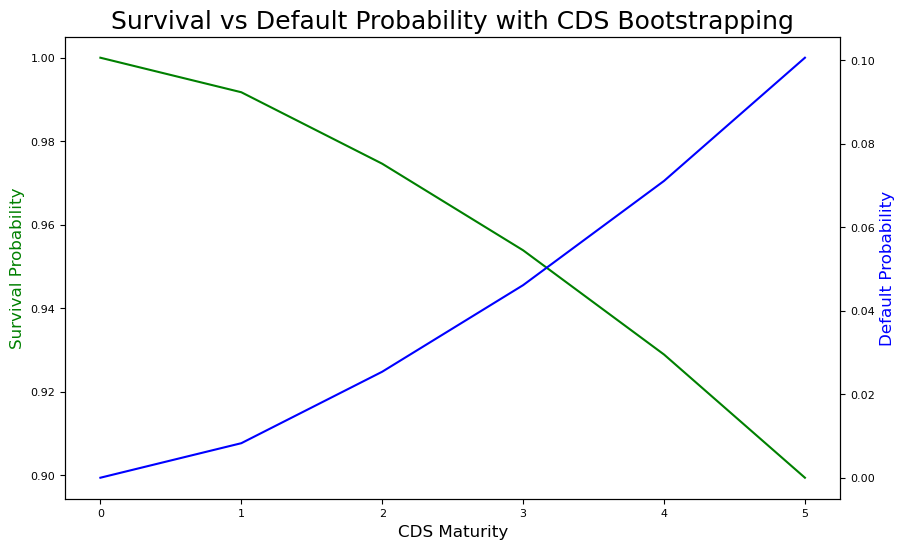

In [10]:
# inputs
maturity = np.arange(6)
discount_factor = [0, 0.97, 0.94, 0.92, 0.89, 0.86]
spread = [0, 50, 77, 94, 109.5, 125]
recovery = 0.40

sp = survival_probability(maturity, discount_factor, spread, recovery, is_plot = True)


### CDS Pricing

In [53]:
def get_cds_spread(maturity, discount_factor, survival, recovery, is_plot= False):
    
    # subsume list of inputs into a dataframe
    df = pd.DataFrame({'Maturity' :maturity,
                       'Df':discount_factor,
                       'Survival' :survival})

    # specify delta_t
    df['dt'] = df['Maturity'].diff(periods = 1).fillna(0)

    # specify recovery rate, Loss given default
    RR = 0.4
    L = 1-RR
    
    # initialize the variables
    nterms = dterms = 0
    
    for i in range(len(df.index)):
        if i == 0:
            df.loc[i,'Spread'] = 0
        else:
            nterms = dterms = 0
            for j in range(1,i+1):
                nterm = L*df.loc[j,'Df']*(df.loc[j-1,'Survival'] - df.loc[j,'Survival'])
                nterms = nterms + nterm
                
                dterm = df.loc[j,'Df']*(df.loc[j,'Survival'])*df.loc[j,'dt']
                dterms = dterms + dterm
                
            df.loc[i,'Spread'] = nterms/dterms*10000
            
    if is_plot:
        df.loc[1:,'Spread'].plot(kind = 'bar')
        plt.title('CDS Spreads')
        plt.xlabel('CDS Maturity')
        plt.ylabel('CDS Spreads (bps)')
        plt.show()
    
    return df

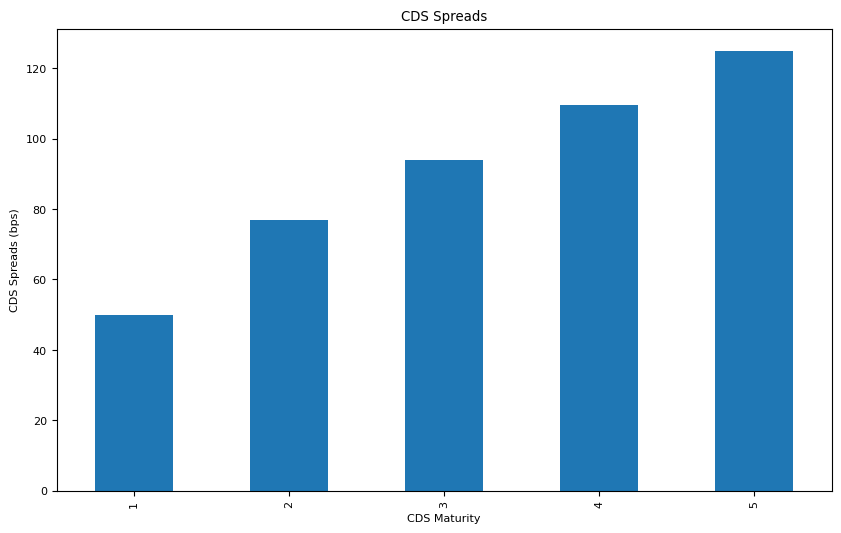

In [54]:
# inputs
maturity = np.arange(6)
discount_factor = [0, 0.97, 0.94, 0.92, 0.89, 0.86]
survival = sp['Survival'].values
recovery = 0.40

spread = get_cds_spread(maturity, discount_factor, survival, recovery, is_plot = True)
